## **Messwerte (Kurzschluss)**

In [25]:
import numpy as np


f_1 = 130 #Erste Frequenz in Hz
f_1_Fehler = 1
omega_1 = f_1 * 2*np.pi
omega_1_Fehler = f_1_Fehler * 2*np.pi

N_1 = 50 #Primärwindungszahl
N_2 = np.array([15, 40, 60, 80 ,85, 100, 120, 140, 170, 200, 240, 290, 350, 420, 500]) #Sekundärwindungszahl

U1_f1 = np.array([0.182, 0.105, 0.068, 0.050 ,0.047, 0.038, 0.033, 0.029, 0.026, 0.039, 0.022,0.021, 0.020, 0.019, 0.019]) #Primärspannung bei Frequenz 1 in Volt
U1_f1_Fehler = 0.002

I1_f1 = np.array([30.2, 30.7, 31.3, 31.6 ,31.6, 31.8, 31.9, 31.9, 32.0, 32.1, 32.1, 32.1, 32.1, 32.1, 32.2]) *10**(-3) #Primärstrom bei Frequenz 1 in Ampere
I1_f1_Fehler = 0.2e-3

I2_f1 = np.array([28.6, 28.3, 22.4, 18.2, 18.2, 15.0, 12.8, 11.1, 9.2, 7.8, 6.5, 5.4, 4.5, 3.8, 3.2]) *10**(-3)#Sekundärstrom bei Frequenz 1 in Ampere
I2_f1_Fehler = 0.2e-3



"""-----------------------------------------------------------------------------------------------------------------------------------"""



f_2 = 320 #Zweite Frequenz in Hz
f_2_Fehler = 1
omega_2 = f_2 * 2*np.pi
omega_2_Fehler = f_2_Fehler * 2*np.pi

U1_f2 = np.array([0.271, 0.121, 0.072, 0.052 ,0.050, 0.038, 0.033, 0.029, 0.026, 0.024, 0.022, 0.021, 0.020, 0.020, 0.019]) #Primärspannung bei Frequenz 2 in Volt
U1_f2_Fehler = 0.002

I1_f2 = np.array([28.1, 30.1, 31.0, 31.3, 31.4, 31.6, 31.7, 31.7, 31.8, 31.9, 31.9, 31.9, 31.9, 32.0, 32.0])*10**(-3) #Primärstrom bei Frequenz 2 in Ampere
I1_f2_Fehler = 0.2e-3

I2_f2 = np.array([42.6, 32.7, 22.9, 18.9, 18.7, 15.7, 12.8, 11.0, 9.1, 7.7, 6.4, 5.3, 4.3, 3.6, 3.0])*10**(-3) #Sekundärstrom bei Frequenz 2 in Ampere
I2_f2_Fehler = 0.2e-3


## **Berechnung der Induktivität für f_1**

In [26]:
import sympy as sp
from Skripte.Fehlerfortpflanzung import Gaußfehler
from IPython.display import display

%store -r L12_f1
%store -r L12_f1_Fehler

#Berechnung von L2
# noinspection PyUnresolvedReferences
L2_f1 = L12_f1 * I1_f1 / I2_f1
L2_f1_Fehler = np.zeros(len(L2_f1), dtype = float)

%store L2_f1

L12p, I1p, I2p = sp.symbols("L_12, I_1, I_2")
expr1 = L12p * I1p / I2p
display(expr1)
Variablen = np.array([L12p, I1p, I2p])

print(f"Induktivitäten für f_1 = {f_1}Hz :")
for i in range(len(L2_f1)):
    # noinspection PyUnresolvedReferences
    L2_f1_Fehler[i] = Gaußfehler(expr1, Variablen, np.array([L12_f1[i], I1_f1[i], I2_f1[i]]), np.array([L12_f1_Fehler[i], I1_f1_Fehler, I2_f1_Fehler]))
    print(f"für N_2 = {N_2[i]} gilt: L_2 = ({L2_f1[i]*10**3} +/- {L2_f1_Fehler[i]*10**3})mH")



Stored 'L2_f1' (ndarray)


I_1*L_12/I_2

Induktivitäten für f_1 = 130Hz :
für N_2 = 15 gilt: L_2 = (3.836576149911694 +/- 0.09902117355717087)mH
für N_2 = 40 gilt: L_2 = (7.840037052359751 +/- 0.13862070522183786)mH
für N_2 = 60 gilt: L_2 = (15.120354295293259 +/- 0.2505707230266813)mH
für N_2 = 80 gilt: L_2 = (21.942229767748014 +/- 0.3804769052872889)mH
für N_2 = 85 gilt: L_2 = (25.096425296861792 +/- 0.428459637597239)mH
für N_2 = 100 gilt: L_2 = (38.34567829888505 +/- 0.7041389360735405)mH
für N_2 = 120 gilt: L_2 = (54.132550336292326 +/- 1.0792168884663973)mH
für N_2 = 140 gilt: L_2 = (72.86480682121471 +/- 1.5871429291656147)mH
für N_2 = 170 gilt: L_2 = (107.1449827266617 +/- 2.66578314871656)mH
für N_2 = 200 gilt: L_2 = (148.87473069596155 +/- 4.215663076116284)mH
für N_2 = 240 gilt: L_2 = (214.73067051910954 +/- 7.088258297547312)mH
für N_2 = 290 gilt: L_2 = (312.232422820618 +/- 12.147477791329113)mH
für N_2 = 350 gilt: L_2 = (451.86839657528225 +/- 20.78829270383897)mH
für N_2 = 420 gilt: L_2 = (641.861887640897 +/-

## **Berechnung der Induktivität für f_2**

In [27]:
%store -r L12_f2
%store -r L12_f2_Fehler

#Berechnung von L2
# noinspection PyUnresolvedReferences
L2_f2 = L12_f2 * I1_f2 / I2_f2
L2_f2_Fehler = np.zeros(len(L2_f2), dtype = float)

%store L2_f2

L12p, I1p, I2p = sp.symbols("L_12, I_1, I_2")
expr1 = L12p * I1p / I2p
display(expr1)
Variablen = np.array([L12p, I1p, I2p])

print(f"Induktivitäten für f_2 = {f_2}Hz :")
for i in range(len(L2_f2)):
    # noinspection PyUnresolvedReferences
    L2_f2_Fehler[i] = Gaußfehler(expr1, Variablen, np.array([L12_f2[i], I1_f2[i], I2_f2[i]]), np.array([L12_f2_Fehler[i], I1_f2_Fehler, I2_f2_Fehler]))
    print(f"für N_2 = {N_2[i]} gilt: L_2 = ({L2_f2[i]} +/- {L2_f2_Fehler[i]})H")

Stored 'L2_f2' (ndarray)


I_1*L_12/I_2

Induktivitäten für f_2 = 320Hz :
für N_2 = 15 gilt: L_2 = (0.002094065543940225 +/- 3.351951411045131e-05)H
für N_2 = 40 gilt: L_2 = (0.006006777039056021 +/- 7.851226078795655e-05)H
für N_2 = 60 gilt: L_2 = (0.013370119332799597 +/- 0.0001846430000839771)H
für N_2 = 80 gilt: L_2 = (0.02161400751373457 +/- 0.00032071698532698377)H
für N_2 = 85 gilt: L_2 = (0.022921870110650784 +/- 0.0003412961627976113)H
für N_2 = 100 gilt: L_2 = (0.03439792555627366 +/- 0.0005617098093677949)H
für N_2 = 120 gilt: L_2 = (0.0507984021988518 +/- 0.0009462260495589595)H
für N_2 = 140 gilt: L_2 = (0.06902197657948267 +/- 0.0014356202361252405)H
für N_2 = 170 gilt: L_2 = (0.10156965563930986 +/- 0.0024548075859124087)H
für N_2 = 200 gilt: L_2 = (0.14153068987938572 +/- 0.003940273447407257)H
für N_2 = 240 gilt: L_2 = (0.20218996174528273 +/- 0.006634454193452455)H
für N_2 = 290 gilt: L_2 = (0.29510777681477196 +/- 0.011520111707949648)H
für N_2 = 350 gilt: L_2 = (0.4396251706138079 +/- 0.02091367927194196)H

## **Kopplungsgrad aus linearer Regression**

I_1/I_2

Kopplungsgrad für f_1 = 130Hz: kappa = 0.9519727489402375 +/- 0.015508538198204757
Kopplungsgrad für f_2 = 320Hz: kappa = 0.9713609779369707 +/- 0.015701108764977594


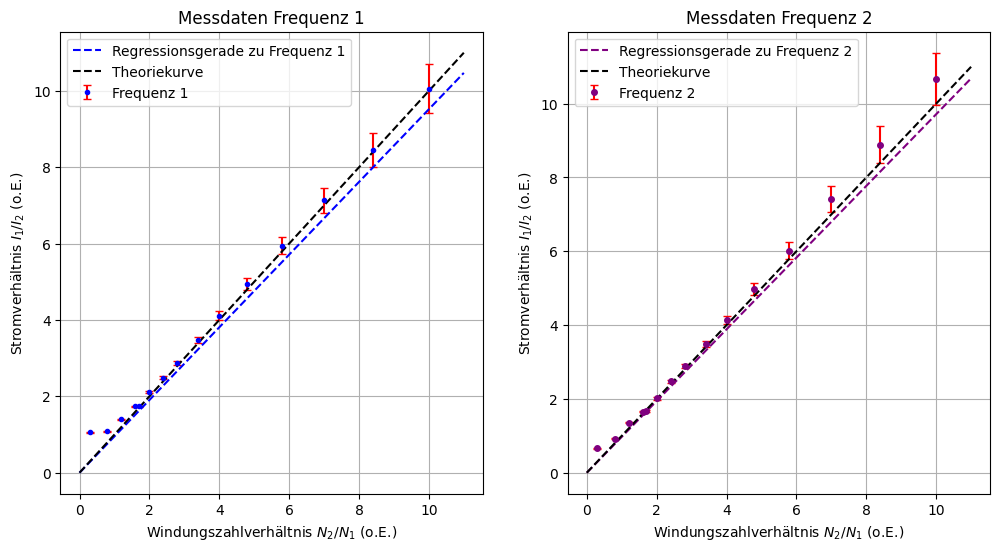

In [28]:
import matplotlib
"""
matplotlib.use("pgf")
matplotlib.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'font.family': 'arial',
    'text.usetex': True,
    'pgf.rcfonts': False,
})
"""

import scipy.optimize
import matplotlib.pyplot as plt

N_Ratio = N_2 / N_1

I1p, I2p = sp.symbols("I_1, I_2")
expr3 = I1p / I2p
display(expr3)
Variablen = np.array([I1p, I2p])

#Frequenz 1
I_Ratio_f1 = I1_f1 / I2_f1
I_Ratio_f1_Fehler = np.zeros(len(I_Ratio_f1), dtype = float)

for i in range(len(I_Ratio_f1_Fehler)):
    I_Ratio_f1_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([I1_f1[i], I2_f1[i]]), np.array([I1_f1_Fehler, I2_f1_Fehler]))

#Frequenz 2
I_Ratio_f2 = I1_f2 / I2_f2
I_Ratio_f2_Fehler = np.zeros(len(I_Ratio_f2), dtype = float)

for i in range(len(I_Ratio_f2_Fehler)):
    I_Ratio_f2_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([I1_f2[i], I2_f2[i]]), np.array([I1_f2_Fehler, I2_f2_Fehler]))

#Lineare Regression

def f(x,k,c):
    return k*x +c #Fit Funktion

coefficients1, pcov1 = scipy.optimize.curve_fit(f, N_Ratio[2:], I_Ratio_f1[2:], sigma= I_Ratio_f1_Fehler[2:], absolute_sigma= True)
kappa_1 = coefficients1[0]
kappa_1_Fehler = np.sqrt(pcov1[0,0])
c_1 = 0

print(f"Kopplungsgrad für f_1 = {f_1}Hz: kappa = {kappa_1} +/- {kappa_1_Fehler}")

coefficients2, pcov2 = scipy.optimize.curve_fit(f, N_Ratio[2:], I_Ratio_f2[2:], sigma= I_Ratio_f2_Fehler[2:], absolute_sigma= True)
kappa_2 = coefficients2[0]
kappa_2_Fehler = np.sqrt(pcov2[0,0])
c_2 = 0

print(f"Kopplungsgrad für f_2 = {f_2}Hz: kappa = {kappa_2} +/- {kappa_2_Fehler}")

#Plot
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.errorbar(N_Ratio, I_Ratio_f1, yerr=I_Ratio_f1_Fehler, fmt="o", label="Frequenz 1", color="blue", markersize=3, capsize=3, ecolor="r")
ax2.errorbar(N_Ratio, I_Ratio_f2, yerr=I_Ratio_f2_Fehler, fmt="o", label="Frequenz 2", color="purple", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(0, np.max(N_Ratio)*1.1, 500)
ax1.plot(xwerte, kappa_1*xwerte + c_1, color = "blue", linestyle = "--", label = "Regressionsgerade zu Frequenz 1")
ax2.plot(xwerte, kappa_2*xwerte + c_2, color = "purple", linestyle = "--", label = "Regressionsgerade zu Frequenz 2")

ax1.plot(xwerte, xwerte, color = "black", linestyle = "--", label = "Theoriekurve")
ax2.plot(xwerte, xwerte, color = "black", linestyle = "--", label = "Theoriekurve")

ax1.set_xlabel(r"Windungszahlverhältnis $N_2/N_1$ (o.E.)")
ax1.set_ylabel(r"Stromverhältnis $I_1/I_2$ (o.E.)")
ax1.grid(True)
ax1.set_title("Messdaten Frequenz 1")
ax1.legend()

ax2.set_xlabel(r"Windungszahlverhältnis $N_2/N_1$ (o.E.)")
ax2.set_ylabel(r"Stromverhältnis $I_1/I_2$ (o.E.)")
ax2.grid(True)
ax2.set_title("Messdaten Frequenz 2")
ax2.legend()

plt.savefig("Kurzschluss.pgf")

## **Kopplungsgrad aus allen Induktivitäten Frequenz 1**

In [29]:
%store -r L1_f1
%store -r L1_f1_Fehler


#Frequenz 1

# noinspection PyUnresolvedReferences
kappa_f1 = L12_f1 / np.sqrt(L1_f1 * L2_f1)
kappa_f1_Fehler = np.zeros(len(kappa_f1), dtype = float)

L1p, L2p, L12p = sp.symbols("L_1, L_2, L_12")
expr4 = L12p / sp.sqrt(L1p * L2p)
display(expr4)
Variablen = np.array([L1p, L2p, L12p])

print(f"Kopplungsgradefür f_1 = {f_1}Hz :")
for i in range(len(kappa_f1)):
    # noinspection PyUnresolvedReferences
    kappa_f1_Fehler[i] = Gaußfehler(expr4, Variablen, np.array([L1_f1[i], L2_f1[i], L12_f1[i]]), np.array([L1_f1_Fehler[i], L2_f1_Fehler[i], L12_f1_Fehler[i]]))
    print(f"für N_2 = {N_2[i]} gilt: kappa = ({kappa_f1[i]} +/- {kappa_f1_Fehler[i]})")




L_12/sqrt(L_1*L_2)

Kopplungsgradefür f_1 = 130Hz :
für N_2 = 15 gilt: kappa = (0.612815111815706 +/- 0.01715552500103302)
für N_2 = 40 gilt: kappa = (0.8527182981574748 +/- 0.01577345598802912)
für N_2 = 60 gilt: kappa = (0.9193547607749274 +/- 0.015008526853387818)
für N_2 = 80 gilt: kappa = (0.8912984461571878 +/- 0.014338650527620483)
für N_2 = 85 gilt: kappa = (0.9532102482609941 +/- 0.014990004249286683)
für N_2 = 100 gilt: kappa = (0.964985563249739 +/- 0.015194801230979198)
für N_2 = 120 gilt: kappa = (0.9753196981883414 +/- 0.015640505415201688)
für N_2 = 140 gilt: kappa = (0.9812725936994298 +/- 0.016210068355791342)
für N_2 = 170 gilt: kappa = (0.9831555459774444 +/- 0.017195465908701888)
für N_2 = 200 gilt: kappa = (0.9794866689793928 +/- 0.018319305786859294)
für N_2 = 240 gilt: kappa = (0.980288322368785 +/- 0.020096805432708233)
für N_2 = 290 gilt: kappa = (0.9820332482542353 +/- 0.02250631783090531)
für N_2 = 350 gilt: kappa = (0.9844914079153276 +/- 0.02558251385853229)
für N_2 = 420 gilt

## **Kopplungsgrad aus allen Induktivitäten Frequenz 2**

In [30]:
%store -r L1_f2
%store -r L1_f2_Fehler

#Frequenz 2

# noinspection PyUnresolvedReferences
kappa_f2 = L12_f2 / np.sqrt(L1_f2 * L2_f2)
kappa_f2_Fehler = np.zeros(len(kappa_f2), dtype = float)

L1p, L2p, L12p = sp.symbols("L_1, L_2, L_12")
expr4 = L12p / sp.sqrt(L1p * L2p)
display(expr4)
Variablen = np.array([L1p, L2p, L12p])

print(f"Kopplungsgradefür f_2 = {f_2}Hz :")
for i in range(len(kappa_f2)):
    # noinspection PyUnresolvedReferences
    kappa_f2_Fehler[i] = Gaußfehler(expr4, Variablen, np.array([L1_f2[i], L2_f2[i], L12_f2[i]]), np.array([L1_f2_Fehler[i], L2_f2_Fehler[i], L12_f2_Fehler[i]]))
    print(f"für N_2 = {N_2[i]} gilt: kappa = ({kappa_f2[i]} +/- {kappa_f2_Fehler[i]})")

L_12/sqrt(L_1*L_2)

Kopplungsgradefür f_2 = 320Hz :
für N_2 = 15 gilt: kappa = (0.7470221212570637 +/- 0.012201301904594581)
für N_2 = 40 gilt: kappa = (0.9066445619640526 +/- 0.011148106730370066)
für N_2 = 60 gilt: kappa = (0.9197641506115477 +/- 0.010871055703126417)
für N_2 = 80 gilt: kappa = (0.9559169525912169 +/- 0.011375497751957986)
für N_2 = 85 gilt: kappa = (0.9708944757273724 +/- 0.011543632556447869)
für N_2 = 100 gilt: kappa = (0.9922331759560796 +/- 0.012159953976097777)
für N_2 = 120 gilt: kappa = (0.9799654887910516 +/- 0.012738138054362103)
für N_2 = 140 gilt: kappa = (0.9816624227777122 +/- 0.013516552762923831)
für N_2 = 170 gilt: kappa = (0.9820448224423086 +/- 0.01478841995698436)
für N_2 = 200 gilt: kappa = (0.9778233455842589 +/- 0.016188851966513852)
für N_2 = 240 gilt: kappa = (0.9714134982593118 +/- 0.018152495382804387)
für N_2 = 290 gilt: kappa = (0.9718753378268041 +/- 0.020861431007851806)
für N_2 = 350 gilt: kappa = (0.9623966340284548 +/- 0.024449080977812704)
für N_2 = 42